# AgroVision AI - training with an Unknown class
Attach these inputs first (+ Add Input): your PlantVillage dataset, Flowers Recognition, Intel Image Classification,
and (best) your own photo dataset of money plant, other plants, walls, paper and handwritten notes.
Every dataset that is NOT the plant-disease dataset becomes the **Unknown** class.

In [1]:
import os, json, random, shutil, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

print("TF:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU'); print("GPU:", gpus)
EPOCHS = 25 if gpus else 12
USE_PRETRAINED = False   # True = MobileNetV2 (needs Internet ON). False = your own CNN from scratch.
IMG = (128, 128); BATCH = 32          # keep IMG the same in main.py
exts = ('.jpg', '.jpeg', '.png')

TF: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
# ---- synthetic Unknown images: paper, handwriting-like scribbles, text, plain colours, noise ----
from PIL import Image, ImageDraw
SYN = '/tmp/synthetic'; shutil.rmtree(SYN, ignore_errors=True); os.makedirs(SYN)
random.seed(1); words = "note math hello class homework today meeting list name date page the and for".split()

def paper():
    bg = random.choice([(255,255,255),(250,248,240),(245,245,235),(235,240,250),(255,253,208)])
    im = Image.new('RGB', (256,256), bg); d = ImageDraw.Draw(im)
    if random.random() < .6:
        for y in range(20, 256, random.choice([16,20,24])): d.line([(0,y),(256,y)], fill=(170,190,230), width=1)
    ink = random.choice([(20,20,40),(10,10,120),(30,30,30),(90,20,20)])
    for _ in range(random.randint(4,10)):
        x, y = random.randint(5,60), random.randint(10,240)
        pts = [(x + i*random.randint(4,9), y + random.randint(-7,7)) for i in range(random.randint(8,24))]
        d.line(pts, fill=ink, width=random.choice([1,2]))
    if random.random() < .5: d.text((random.randint(5,120), random.randint(5,230)), " ".join(random.choices(words,k=4)), fill=ink)
    return im

def plain():
    c = tuple(random.randint(0,255) for _ in range(3)); im = Image.new('RGB',(256,256),c); d = ImageDraw.Draw(im)
    for _ in range(random.randint(0,6)):
        x0,y0 = random.randint(0,200),random.randint(0,200)
        d.rectangle([x0,y0,x0+random.randint(20,120),y0+random.randint(20,120)], fill=tuple(random.randint(0,255) for _ in range(3)))
    return im

def noise():
    return Image.fromarray(np.random.randint(0,255,(256,256,3),dtype=np.uint8))

makers = [paper]*5 + [plain]*2 + [noise]
for i in range(700):
    random.choice(makers)().save(f'{SYN}/syn_{i}.jpg', quality=85)
print("synthetic images:", len(os.listdir(SYN)))

synthetic images: 700


In [3]:
# ---- build /tmp/merged: plant classes + Unknown ----
MERGED = '/tmp/merged'; shutil.rmtree(MERGED, ignore_errors=True); os.makedirs(MERGED)

def has_images(p):
    try: return any(f.lower().endswith(exts) for f in os.listdir(p))
    except Exception: return False

plant_root = None
for root, dirs, files in os.walk('/kaggle/input'):
    if any('healthy' in d.lower() and has_images(os.path.join(root, d)) for d in dirs):
        plant_root = root; break
assert plant_root, "Plant disease dataset not found - add PlantVillage with + Add Input"
print("Plant data:", plant_root)

for c in sorted(os.listdir(plant_root)):
    src = os.path.join(plant_root, c)
    if os.path.isdir(src) and has_images(src):
        dst = os.path.join(MERGED, c); os.makedirs(dst)
        for f in os.listdir(src):
            if f.lower().endswith(exts): os.symlink(os.path.join(src, f), os.path.join(dst, f))

unknown = []
for root, dirs, files in os.walk('/kaggle/input'):
    if root.startswith(plant_root): dirs[:] = []; continue
    unknown += [os.path.join(root, f) for f in files if f.lower().endswith(exts)]
random.seed(42); random.shuffle(unknown); unknown = unknown[:3000]
print("Unknown images from other datasets:", len(unknown))

unk = os.path.join(MERGED, 'Unknown'); os.makedirs(unk)
for i, p in enumerate(unknown): os.symlink(p, os.path.join(unk, f'{i}_{os.path.basename(p)}'))
for f in os.listdir(SYN): os.symlink(os.path.join(SYN, f), os.path.join(unk, f))

DATA = MERGED
for c in sorted(os.listdir(MERGED)): print(f"  {c}: {len(os.listdir(os.path.join(MERGED, c)))}")

Plant data: /kaggle/input/datasets/arjuntejaswi/plant-village/PlantVillage
Unknown images from other datasets: 15
  Pepper__bell___Bacterial_spot: 997
  Pepper__bell___healthy: 1478
  Potato___Early_blight: 1000
  Potato___Late_blight: 1000
  Potato___healthy: 152
  Tomato_Bacterial_spot: 2127
  Tomato_Early_blight: 1000
  Tomato_Late_blight: 1909
  Tomato_Leaf_Mold: 952
  Tomato_Septoria_leaf_spot: 1771
  Tomato_Spider_mites_Two_spotted_spider_mite: 1676
  Tomato__Target_Spot: 1404
  Tomato__Tomato_YellowLeaf__Curl_Virus: 3208
  Tomato__Tomato_mosaic_virus: 373
  Tomato_healthy: 1591
  Unknown: 715


In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(DATA, validation_split=0.2, subset='training', seed=42, image_size=IMG, batch_size=BATCH)
val_full = tf.keras.utils.image_dataset_from_directory(DATA, validation_split=0.2, subset='validation', seed=42, image_size=IMG, batch_size=BATCH)
class_names = train_ds.class_names; num_classes = len(class_names)
print(num_classes, class_names)
n = tf.data.experimental.cardinality(val_full).numpy()
test_ds = val_full.take(n // 2); val_ds = val_full.skip(n // 2)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE); test_ds = test_ds.cache().prefetch(AUTOTUNE)

Found 21353 files belonging to 16 classes.
Using 17083 files for training.


I0000 00:00:1791352689.705509      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791352689.709090      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 21353 files belonging to 16 classes.
Using 4270 files for validation.
16 ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy', 'Unknown']


In [5]:
augment = models.Sequential([
    layers.RandomFlip('horizontal_and_vertical'), layers.RandomRotation(0.25), layers.RandomZoom((-0.3, 0.3)),
    layers.RandomTranslation(0.15, 0.15), layers.RandomBrightness(0.3), layers.RandomContrast(0.3)])

if USE_PRETRAINED:
    base = tf.keras.applications.MobileNetV2(input_shape=(*IMG, 3), include_top=False, weights='imagenet'); base.trainable = False
    model = models.Sequential([layers.Input(shape=(*IMG, 3)), augment, layers.Rescaling(1./127.5, offset=-1), base,
        layers.GlobalAveragePooling2D(), layers.Dropout(0.3), layers.Dense(num_classes, activation='softmax')])
else:
    blocks = []
    for f in (32, 64, 128, 256):
        blocks += [layers.Conv2D(f, 3, activation='relu', padding='same'), layers.BatchNormalization(), layers.MaxPooling2D()]
    model = models.Sequential([layers.Input(shape=(*IMG, 3)), augment, layers.Rescaling(1./255), *blocks,
        layers.GlobalAveragePooling2D(), layers.Dense(256, activation='relu'), layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')])

model.compile(optimizer=tf.keras.optimizers.Adam(3e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         4,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 460,240 (1.76 MB)

 Trainable params: 459,280 (1.75 MB)

 Non-trainable params: 960 (3.75 KB)

In [6]:
cb = [tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
      tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2)]
history = model.fit(train_ds, validation_data=val_ds, epochs=(6 if USE_PRETRAINED else EPOCHS), callbacks=cb)

if USE_PRETRAINED:   # phase 2: fine-tune the top of MobileNetV2
    base.trainable = True
    for l in base.layers[:-30]: l.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=cb)
    for k in h2.history: history.history[k] += h2.history[k]

Epoch 1/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 73s 59ms/step - accuracy: 0.4912 - loss: 1.6092 - val_accuracy: 0.2310 - val_loss: 3.3988 - learning_rate: 3.0000e-04
Epoch 2/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 25s 47ms/step - accuracy: 0.6677 - loss: 1.0263 - val_accuracy: 0.4746 - val_loss: 1.8983 - learning_rate: 3.0000e-04
Epoch 3/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 26s 48ms/step - accuracy: 0.7527 - loss: 0.7586 - val_accuracy: 0.5240 - val_loss: 1.7504 - learning_rate: 3.0000e-04
Epoch 4/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 25s 47ms/step - accuracy: 0.8097 - loss: 0.5851 - val_accuracy: 0.5974 - val_loss: 1.4444 - learning_rate: 3.0000e-04
Epoch 5/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 25s 46ms/step - accuracy: 0.8393 - loss: 0.4854 - val_accuracy: 0.6834 - val_loss: 0.9401 - learning_rate: 3.0000e-04
Epoch 6/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 25s 47ms/step - accuracy: 0.8658 - loss: 0.4089 - val_accuracy: 0.7686 - val_loss: 0.7532 - learning_rate: 3.0000e-04
Epoch 7/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 25s 47ms/ste

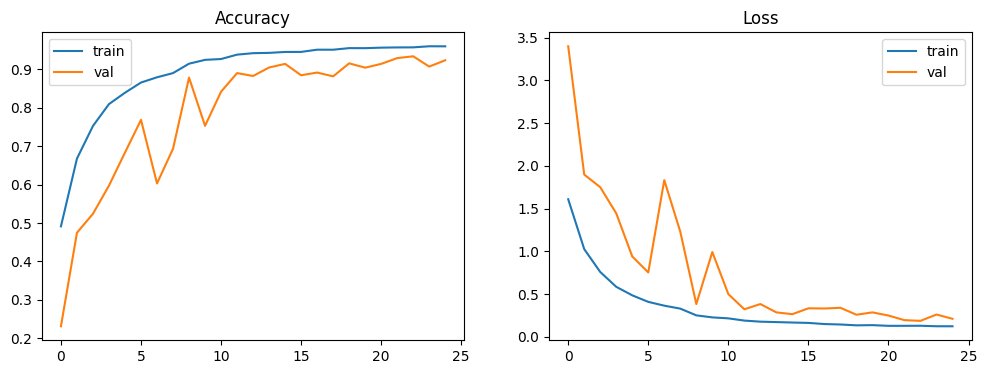

In [7]:
h = history.history
plt.figure(figsize=(12,4))
plt.subplot(1,2,1); plt.plot(h['accuracy'], label='train'); plt.plot(h['val_accuracy'], label='val'); plt.title('Accuracy'); plt.legend()
plt.subplot(1,2,2); plt.plot(h['loss'], label='train'); plt.plot(h['val_loss'], label='val'); plt.title('Loss'); plt.legend()
plt.show()

Test accuracy: 92.82%
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.95      0.97      0.96       103
                     Pepper__bell___healthy       1.00      1.00      1.00       148
                      Potato___Early_blight       0.85      1.00      0.92        93
                       Potato___Late_blight       0.93      0.96      0.95       101
                           Potato___healthy       0.94      1.00      0.97        16
                      Tomato_Bacterial_spot       0.94      0.99      0.96       222
                        Tomato_Early_blight       0.95      0.62      0.75        89
                         Tomato_Late_blight       0.87      0.92      0.90       150
                           Tomato_Leaf_Mold       1.00      0.91      0.95        99
                  Tomato_Septoria_leaf_spot       0.99      0.74      0.85       206
Tomato_Spider_mites_Two_spotted_spider_mit

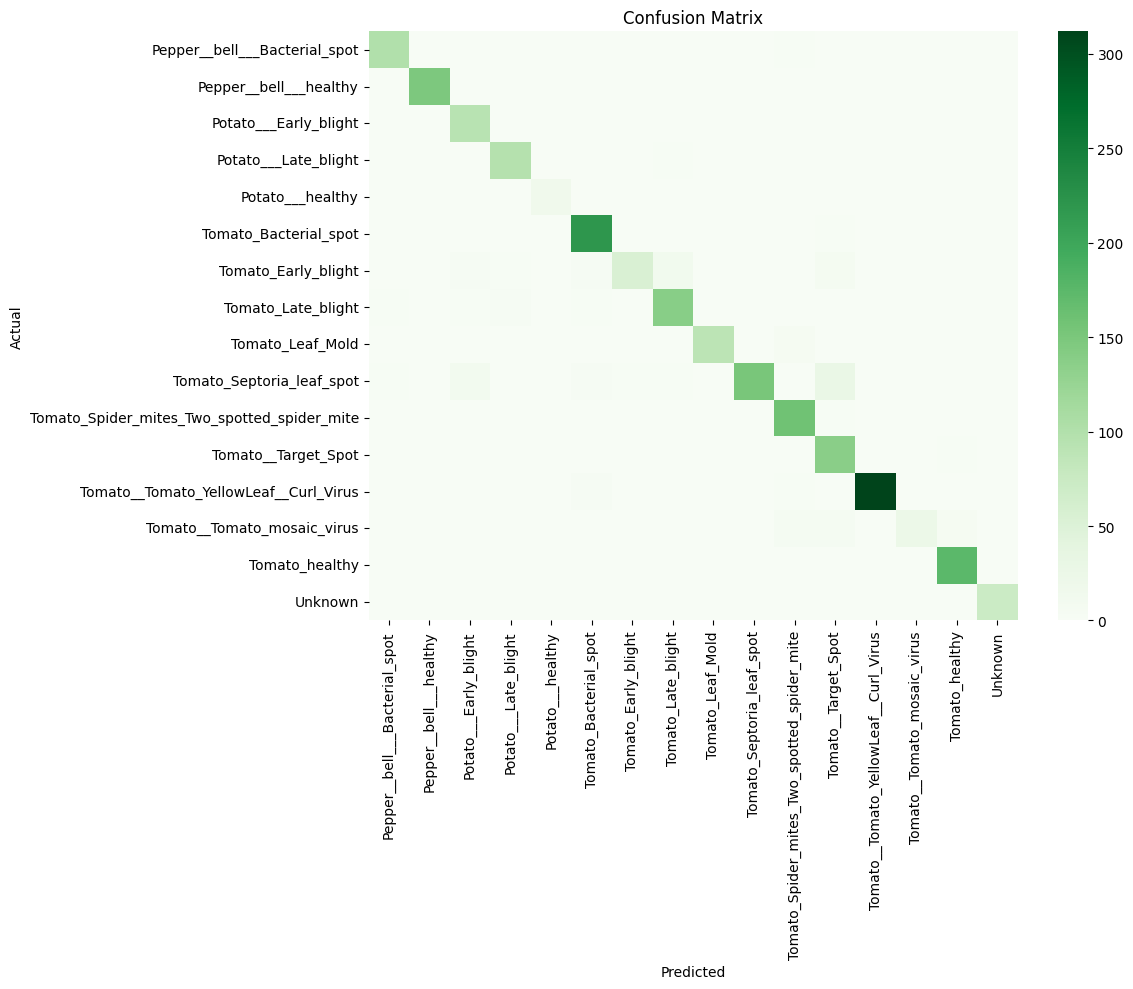

Unknown recall (non-leaf images correctly rejected): 98.6%


In [8]:
print(f"Test accuracy: {model.evaluate(test_ds, verbose=0)[1]*100:.2f}%")
y_true, y_pred = [], []
for x, y in test_ds:
    y_true += list(y.numpy()); y_pred += list(np.argmax(model.predict(x, verbose=0), axis=1))
print(classification_report(y_true, y_pred, target_names=class_names))
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12,10)); sns.heatmap(cm, cmap='Greens', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix'); plt.tight_layout(); plt.show()
u = class_names.index('Unknown'); mask = np.array(y_true) == u
print(f"Unknown recall (non-leaf images correctly rejected): {(np.array(y_pred)[mask]==u).mean()*100:.1f}%")

In [9]:
model.save('/kaggle/working/agrovision_cnn.keras')
with open('/kaggle/working/class_names.json', 'w') as f: json.dump(class_names, f)
print("Saved:", os.listdir('/kaggle/working'))

Saved: ['class_names.json', 'agrovision_cnn.keras', '__notebook__.ipynb']


In [10]:
from sklearn.metrics import accuracy_score, f1_score

print("Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
print("Macro F1:", round(f1_score(y_true, y_pred, average='macro'), 4))

cm2 = cm.copy()
np.fill_diagonal(cm2, 0)
i, j = np.unravel_index(cm2.argmax(), cm2.shape)
print("Most frequent error:", class_names[i], "predicted as", class_names[j], "-", cm2[i, j], "images")

Accuracy: 92.82 %
Macro F1: 0.9133
Most frequent error: Tomato_Septoria_leaf_spot predicted as Tomato__Target_Spot - 29 images


In [11]:
from skimage.feature import local_binary_pattern
from skimage.color import rgb2gray
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def feats(img):
    h = np.concatenate([np.histogram(img[..., c], bins=16, range=(0, 255))[0] for c in range(3)]).astype(float)
    h /= h.sum()
    g = (rgb2gray(img) * 255).astype(np.uint8)
    lbp = local_binary_pattern(g, 8, 1, 'uniform')
    l = np.histogram(lbp, bins=10, range=(0, 10))[0].astype(float)
    l /= l.sum()
    return np.concatenate([h, l])

def extract(ds):
    X, y = [], []
    for xb, yb in ds:
        for im, lab in zip(xb.numpy().astype('uint8'), yb.numpy()):
            X.append(feats(im))
            y.append(lab)
    return np.array(X), np.array(y)

Xtr, ytr = extract(train_ds)
Xte, yte = extract(test_ds)
svm = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=10)).fit(Xtr, ytr)
p = svm.predict(Xte)
print("SVM accuracy:", round(accuracy_score(yte, p) * 100, 2), "%")
print("SVM macro F1:", round(f1_score(yte, p, average='macro'), 4))

SVM accuracy: 91.56 %
SVM macro F1: 0.8985


In [12]:
from sklearn.metrics import precision_score, recall_score
print(round(precision_score(yte, p, average='macro'), 2), round(recall_score(yte, p, average='macro'), 2))

0.91 0.89
